# Étape 1 — Chargement et Analyse Exploratoire des Données (EDA)

**Projet — Prédiction du risque en santé mentale chez les étudiants universitaires**

Avant tout prétraitement ou entraînement de modèle, cette étape consiste à **comprendre en profondeur le jeu de données**. Concrètement :

1. Comprendre la **structure générale** du jeu de données (types de données, dimensions, aperçus) ;
2. Vérifier les **valeurs manquantes**, les **doublons**, les **incohérences** et les **valeurs aberrantes** ;
3. Produire des **statistiques descriptives** ;
4. Étudier la **distribution de la variable cible** et l'éventuel **déséquilibre des classes** ;
5. Analyser les **relations entre les variables explicatives et la cible** ;
6. Examiner les **corrélations entre les variables** ;
7. Identifier les **variables les plus fortement liées au niveau de risque**.

## 0. Imports et configuration

In [2]:
# Librairies nécessaires à l'analyse exploratoire
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# On ignore les avertissements pour garder des sorties lisibles
warnings.filterwarnings("ignore")

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Chemin des données (relatif au dossier notebooks/)
DATA_PATH = "../data/student_mental_health.csv"


## 1. Chargement des données

In [3]:
df = pd.read_csv(DATA_PATH)

print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")

df.head()

Dimensions : 2000 lignes x 17 colonnes


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 2. Structure générale : dimensions et types

In [4]:
# Types de chaque colonne + nombre de valeurs non nulles
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [5]:
# Séparation des variables par type
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols and c != 'Student_ID']

print(f"Variables numériques ({len(numeric_cols)}) :")
for c in numeric_cols:
    print(f"   - {c}")

print(f"\nVariables catégorielles ({len(categorical_cols)}) :")
for c in categorical_cols:
    print(f"   - {c}")

Variables numériques (10) :
   - Age
   - Year_of_Study
   - Sleep_Hours
   - Study_Hours_Per_Week
   - GPA
   - Social_Media_Hours
   - Screen_Time_Hours
   - Financial_Stress
   - Family_Support
   - Attendance_Rate

Variables catégorielles (6) :
   - Gender
   - Physical_Activity
   - Part_Time_Job
   - Diet_Quality
   - Previous_Mental_Health_History
   - Mental_Health_Risk


## 3. Valeurs manquantes

Total de cellules manquantes : 419 (1.23 % du tableau)


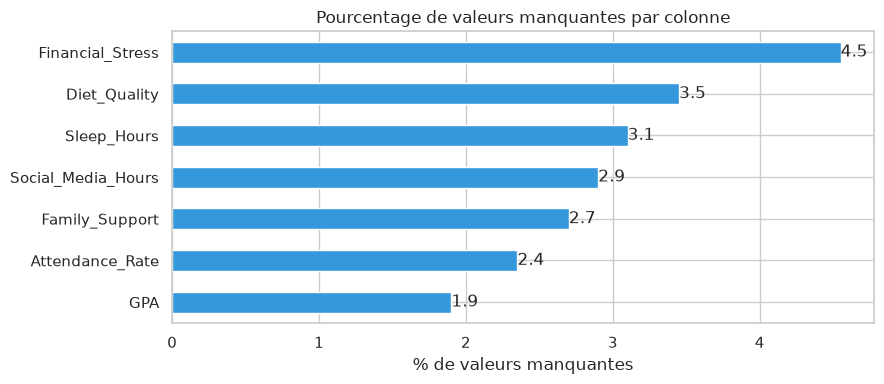

,Valeurs manquantes,Pourcentage (%)
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


In [6]:
# Tableau récapitulatif des valeurs manquantes
missing = pd.DataFrame(
    {
        "Valeurs manquantes": df.isna().sum(),
        "Pourcentage (%)": (df.isna().mean() * 100).round(2),
    }
)
missing = missing[missing["Valeurs manquantes"] > 0].sort_values(
    "Pourcentage (%)", ascending=False
)

total_na = int(df.isna().sum().sum())
print(f"Total de cellules manquantes : {total_na} ({total_na / df.size * 100:.2f} % du tableau)")

fig, ax = plt.subplots(figsize=(9, 4))
missing["Pourcentage (%)"].sort_values().plot(kind="barh", color="#3498db", ax=ax)
ax.set_title("Pourcentage de valeurs manquantes par colonne")
ax.set_xlabel("% de valeurs manquantes")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")
plt.tight_layout()
plt.show()

missing

## 4. Doublons

In [7]:
print(f"Lignes entièrement dupliquées      : {df.duplicated().sum()}")
print(f"Identifiants Student_ID dupliqués : {df['Student_ID'].duplicated().sum()}")
print(f"Identifiants uniques              : {df['Student_ID'].nunique()} / {len(df)}")

Lignes entièrement dupliquées      : 0
Identifiants Student_ID dupliqués : 0
Identifiants uniques              : 2000 / 2000


## 5. Incohérences

In [8]:
# 1) Vérification des bornes documentées pour les variables numériques
checks = {
    "GPA hors [1.5, 4.0]": ((df["GPA"] < 1.5) | (df["GPA"] > 4.0)).sum(),
    "Stress financier hors [1, 10]": ((df["Financial_Stress"] < 1) | (df["Financial_Stress"] > 10)).sum(),
    "Soutien familial hors [1, 10]": ((df["Family_Support"] < 1) | (df["Family_Support"] > 10)).sum(),
    "Assiduité hors [30, 100]": ((df["Attendance_Rate"] < 30) | (df["Attendance_Rate"] > 100)).sum(),
    "Écran < Réseaux sociaux": (df["Screen_Time_Hours"] < df["Social_Media_Hours"]).sum(),
}
print("── Vérification des bornes numériques ──")
for label, n in checks.items():
    print(f"{label:45s}: {n} ligne(s)")

# 2) Cohérence des modalités des variables catégorielles
print("\n── Modalités des variables catégorielles ──")
for col in categorical_cols:
    modalites = sorted(df[col].dropna().unique().tolist())
    print(f"{col:32s}: {modalites}")

── Vérification des bornes numériques ──
GPA hors [1.5, 4.0]                          : 0 ligne(s)
Stress financier hors [1, 10]                : 0 ligne(s)
Soutien familial hors [1, 10]                : 0 ligne(s)
Assiduité hors [30, 100]                     : 0 ligne(s)
Écran < Réseaux sociaux                      : 37 ligne(s)

── Modalités des variables catégorielles ──
Gender                          : ['Female', 'Male', 'Non-binary']
Physical_Activity               : ['High', 'Low', 'Moderate']
Part_Time_Job                   : ['No', 'Yes']
Diet_Quality                    : ['Average', 'Good', 'Poor']
Previous_Mental_Health_History  : ['No', 'Yes']
Mental_Health_Risk              : ['High', 'Low', 'Medium']


## 6. Valeurs aberrantes (méthode IQR)

In [9]:
outliers = []
k = 2  # Facteur pour l'IQR
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outliers.append(
        {
            "Variable": col,
            "Borne inf. (IQR)": round(lower, 2),
            "Borne sup. (IQR)": round(upper, 2),
            "Nb aberrantes": n_out,
            "k": k,
            "% du dataset": round(n_out / len(df) * 100, 2),
        }
    )

pd.DataFrame(outliers).sort_values("% du dataset", ascending=False).reset_index(drop=True)

,Variable,Borne inf. (IQR),Borne sup. (IQR),Nb aberrantes,k,% du dataset
0,Social_Media_Hours,2.27,9.65,3,2,0.15
1,Attendance_Rate,60.90,109.40,1,2,0.05
2,Year_of_Study,-5.00,10.00,0,2,0.00
3,Age,14.00,29.00,0,2,0.00
4,Study_Hours_Per_Week,0.00,40.00,0,2,0.00
5,Sleep_Hours,2.80,10.80,0,2,0.00
6,GPA,1.38,3.73,0,2,0.00
7,Screen_Time_Hours,2.80,14.30,0,2,0.00
8,Financial_Stress,-1.30,13.20,0,2,0.00
9,Family_Support,-0.70,13.80,0,2,0.00


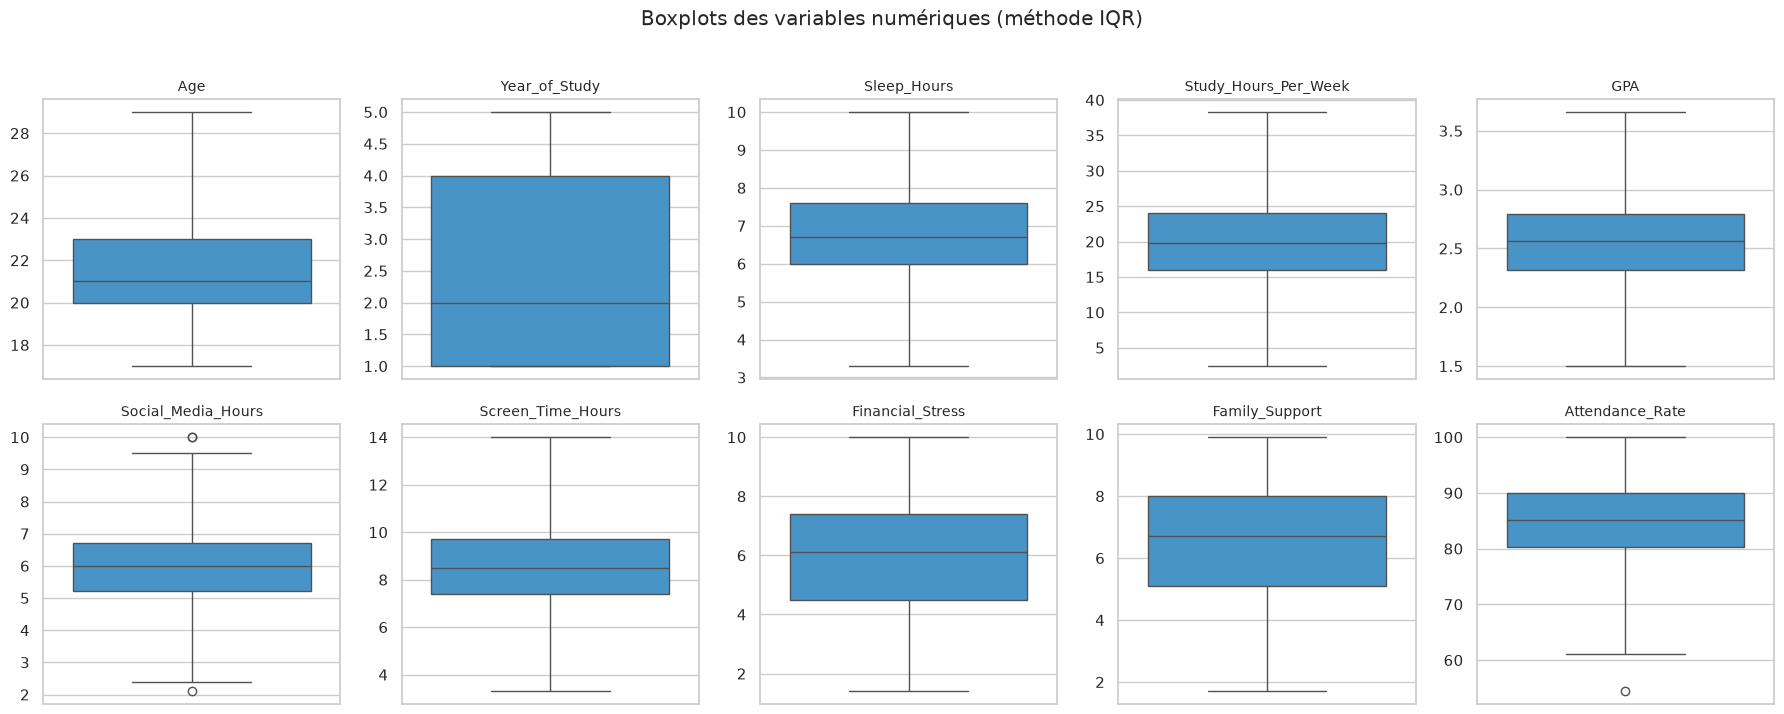

In [10]:
# Boxplots des variables numériques pour visualiser les valeurs extrêmes
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="#3498db", whis=k)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Boxplots des variables numériques (méthode IQR)", y=1.02)
plt.tight_layout()
plt.show()

## 7. Statistiques descriptives

In [11]:
# Statistiques descriptives des variables numériques
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.13,2.14,17.0,20.00,21.00,23.00,29.00
Year_of_Study,2000.0,2.63,1.32,1.0,1.00,2.00,4.00,5.00
Sleep_Hours,1938.0,6.76,1.13,3.3,6.00,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,20.00,5.72,2.4,16.00,19.80,24.00,38.30
GPA,1962.0,2.56,0.34,1.5,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.01,1.15,2.1,5.22,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.55,1.66,3.3,7.40,8.50,9.70,14.00
Financial_Stress,1909.0,5.96,1.89,1.4,4.50,6.10,7.40,10.00
Family_Support,1946.0,6.52,1.84,1.7,5.10,6.70,8.00,9.90
Attendance_Rate,1953.0,85.08,7.22,54.4,80.30,85.10,90.00,100.00


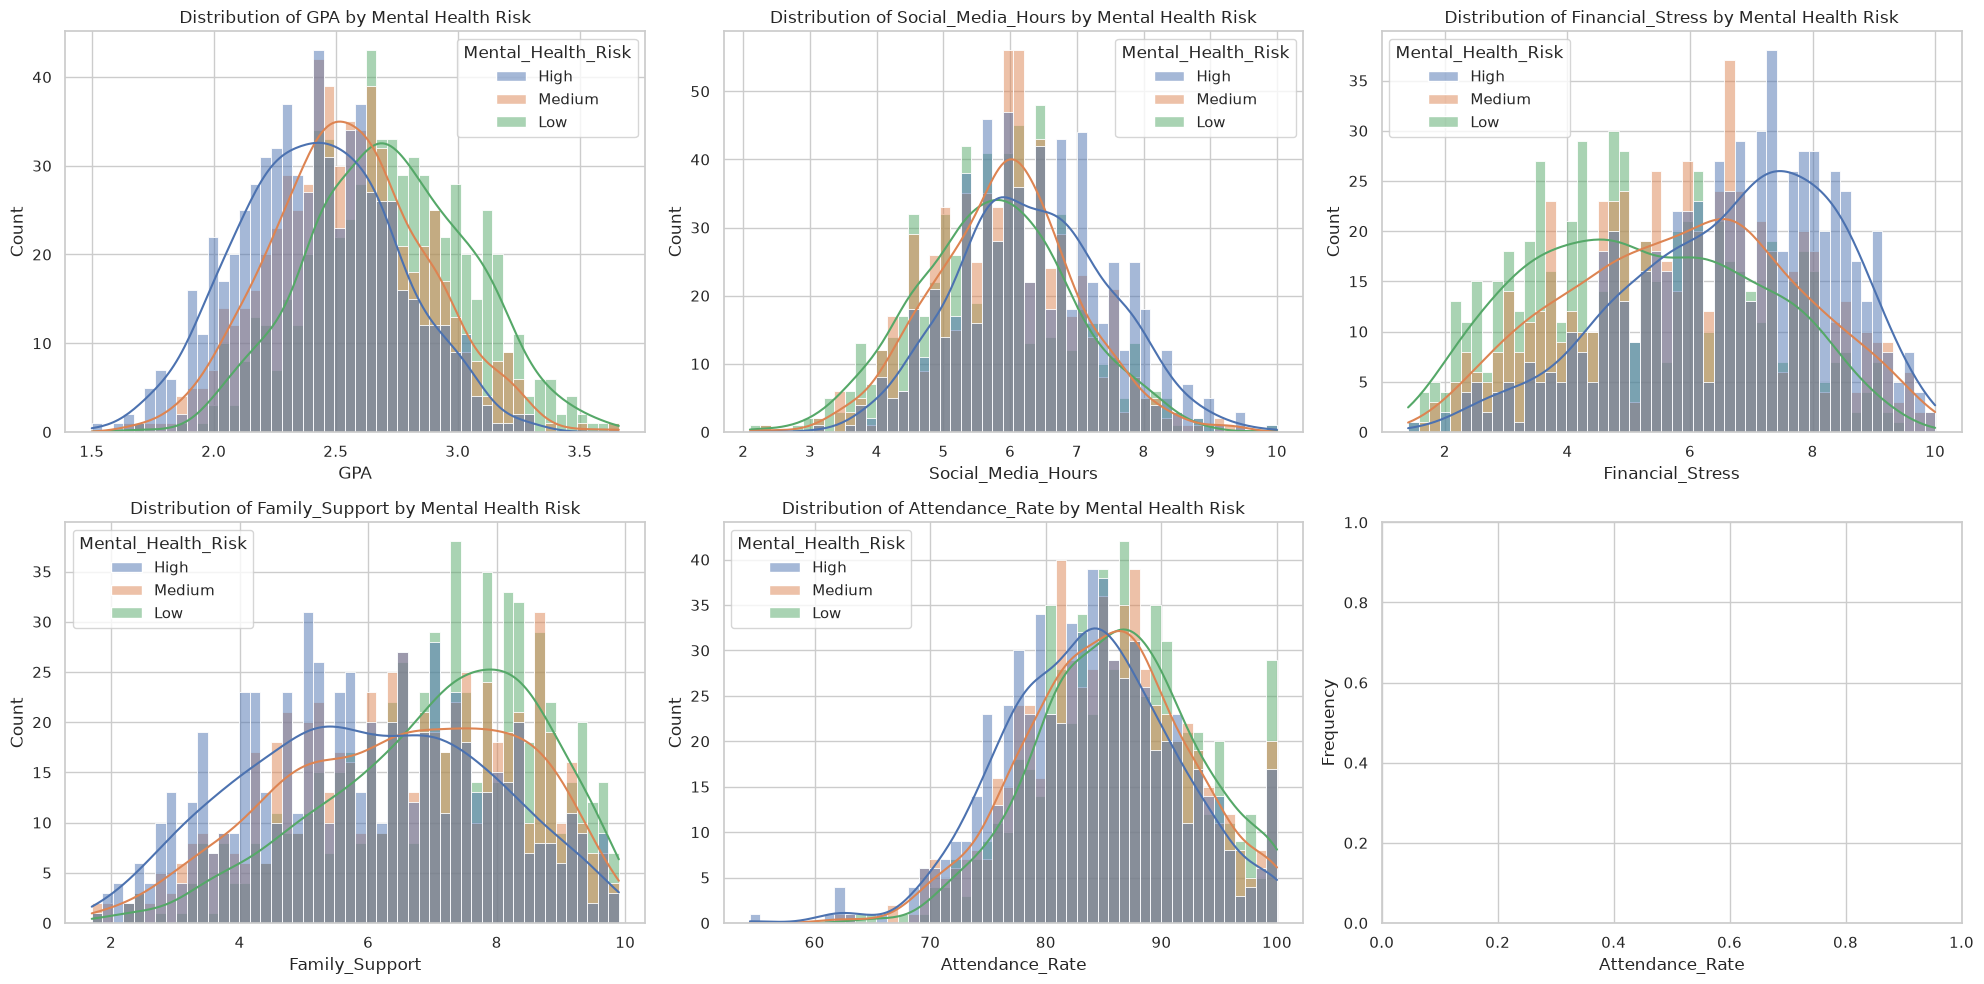

In [32]:
fig , ax = plt.subplots(2 , 3,figsize=(20, 10))

columns_to_plot = ['GPA', 'Social_Media_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

for i, (col, ax) in enumerate(zip(columns_to_plot, ax.flatten())):
    sns.histplot(data=df, x=col, kde=True, bins=50, hue='Mental_Health_Risk' ,ax=ax)
    ax.set_title(f'Distribution of {col} by Mental Health Risk')
    plt.xlabel(col)
    plt.ylabel('Frequency')


plt.tight_layout()


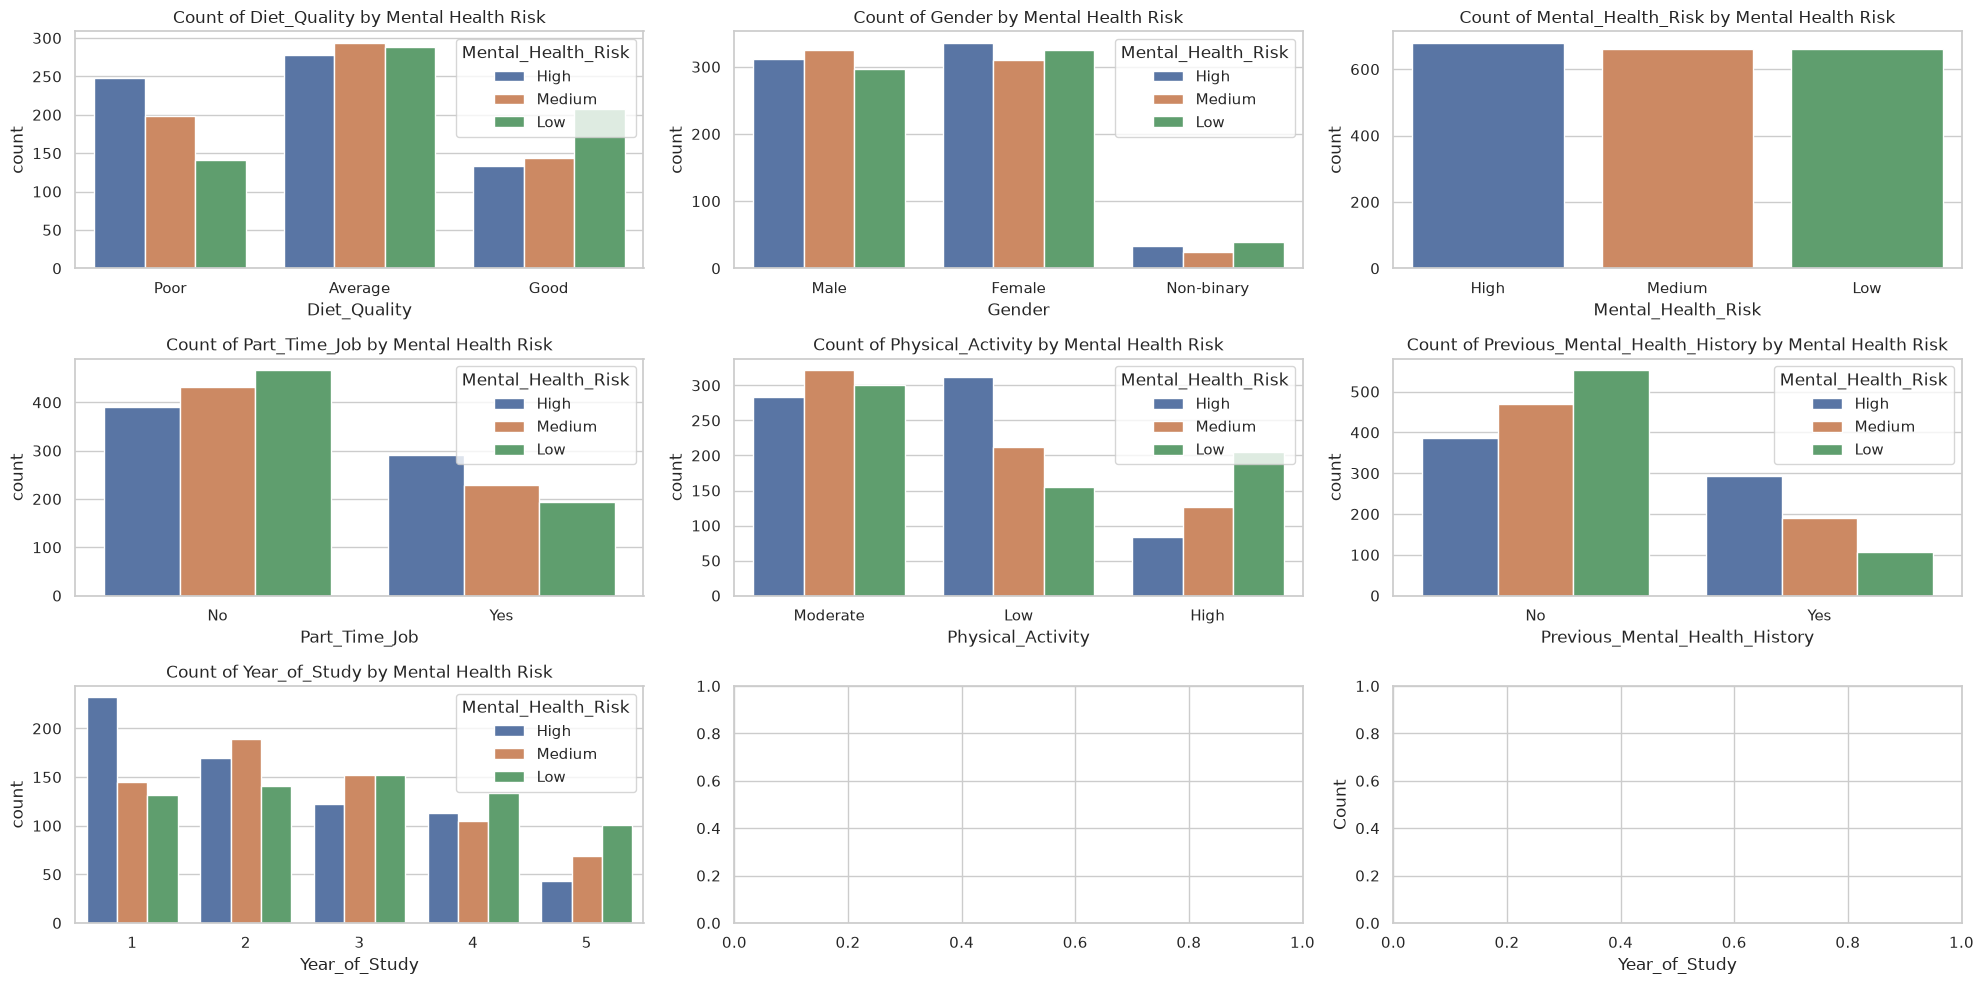

In [31]:
cat_col = df.select_dtypes(include='object').columns.drop('Student_ID').union(['Year_of_Study']).tolist()

fig, ax = plt.subplots(3 , 3,figsize=(20, 10))

for i, (col, ax) in enumerate(zip(cat_col, ax.flatten())):
    sns.countplot(data=df, x=col, hue='Mental_Health_Risk', ax=ax)
    ax.set_title(f'Count of {col} by Mental Health Risk')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()


## 8. Distribution de la variable cible et équilibre des classes

Valeurs manquantes dans la cible : 0


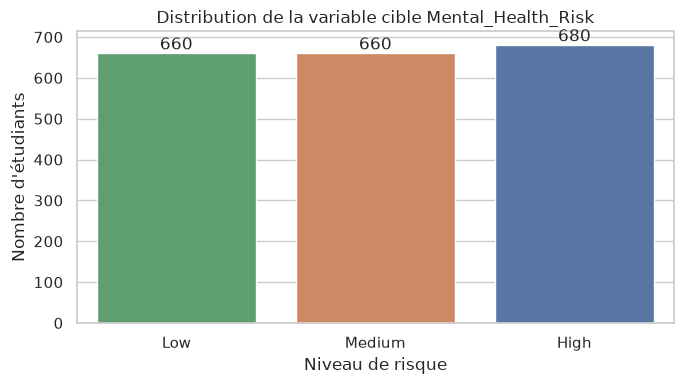

,Effectif,Pourcentage (%)
Mental_Health_Risk,,
Low,660,33.0
Medium,660,33.0
High,680,34.0


In [14]:
# Effectifs et proportions de chaque classe de risque
RISK_ORDER = ["Low", "Medium", "High"]
target_dist = pd.DataFrame(
    {
        "Effectif": df["Mental_Health_Risk"].value_counts(),
        "Pourcentage (%)": (df["Mental_Health_Risk"].value_counts(normalize=True) * 100).round(1),
    }
).reindex(RISK_ORDER)

print(f"Valeurs manquantes dans la cible : {df['Mental_Health_Risk'].isna().sum()}")

# Diagramme en barres de la répartition des classes
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="Mental_Health_Risk", order=RISK_ORDER,
              hue="Mental_Health_Risk", legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("Distribution de la variable cible Mental_Health_Risk")
ax.set_xlabel("Niveau de risque")
ax.set_ylabel("Nombre d'étudiants")
plt.tight_layout()
plt.show()

target_dist

## 9. Relations entre les variables explicatives et la cible

### 9.1 Variables numériques — moyennes par classe

In [15]:
# Moyenne des variables numériques par niveau de risque
means_by_risk = (
    df.groupby("Mental_Health_Risk")[numeric_cols]
    .mean()
    .reindex(RISK_ORDER)
    .T.round(2)
)
means_by_risk

Mental_Health_Risk,Low,Medium,High
Age,21.11,21.14,21.14
Year_of_Study,2.90,2.64,2.36
Sleep_Hours,7.52,6.73,6.04
Study_Hours_Per_Week,21.70,19.98,18.36
GPA,2.72,2.55,2.42
Social_Media_Hours,5.76,5.92,6.35
Screen_Time_Hours,8.26,8.42,8.96
Financial_Stress,5.24,5.90,6.69
Family_Support,7.09,6.53,5.96
Attendance_Rate,86.33,85.19,83.77


### 9.2 Variables numériques — distributions par classe

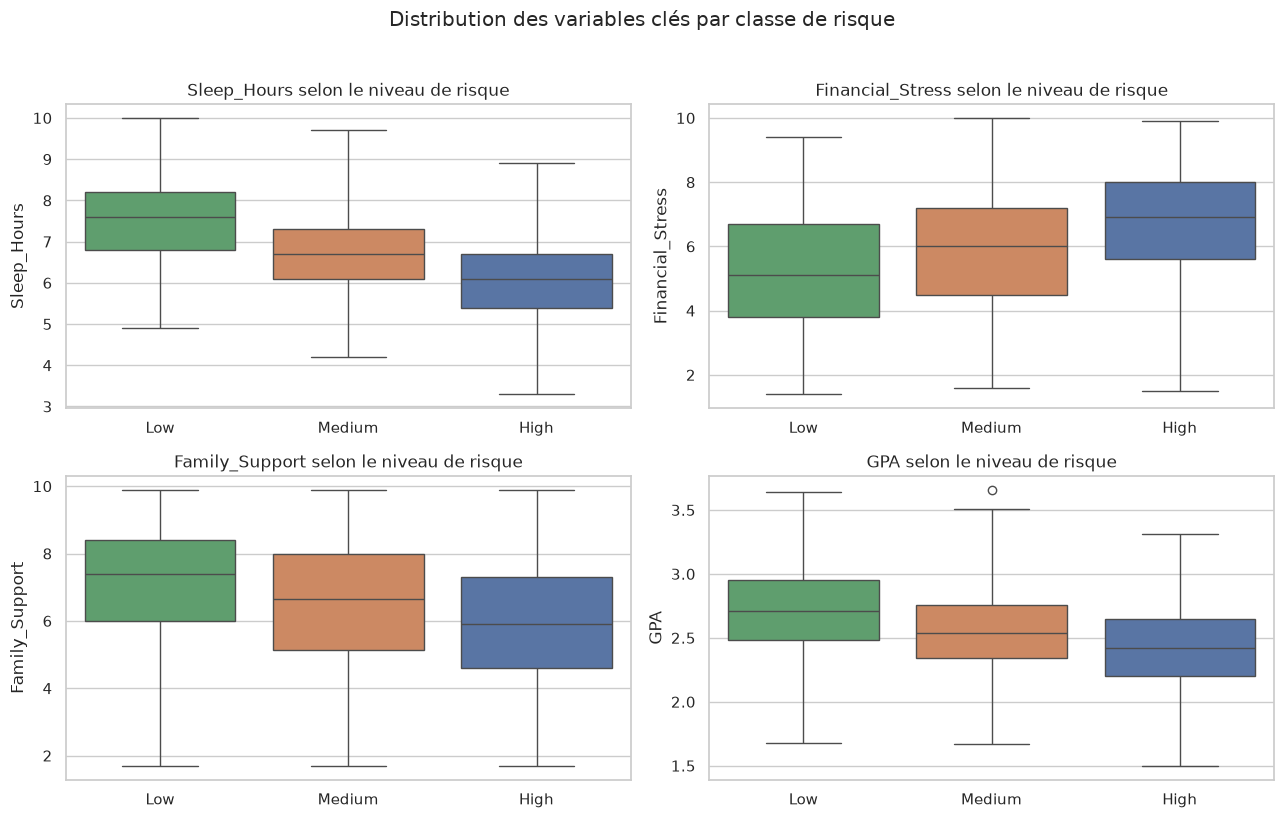

In [16]:
# Boxplots des variables les plus discriminantes selon le niveau de risque
top_num = ["Sleep_Hours", "Financial_Stress", "Family_Support", "GPA"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, top_num):
    sns.boxplot(data=df, x="Mental_Health_Risk", y=col, order=RISK_ORDER,
                hue="Mental_Health_Risk",whis=k , legend=False, ax=ax)
    ax.set_title(f"{col} selon le niveau de risque")
    ax.set_xlabel("")
plt.suptitle("Distribution des variables clés par classe de risque", y=1.02)
plt.tight_layout()
plt.show()

### 9.3 Variables catégorielles vs cible

In [17]:
cat_features = [
    "Physical_Activity",
    "Previous_Mental_Health_History",
    "Diet_Quality",
    "Part_Time_Job",
    "Gender",
]
for col in cat_features:
    ct = pd.crosstab(df[col], df["Mental_Health_Risk"], normalize="index") * 100
    ct = ct.reindex(columns=RISK_ORDER).round(1)
    print(f"── {col} (en % par modalité) ──")
    print(f"{ct} \n")

── Physical_Activity (en % par modalité) ──
Mental_Health_Risk   Low  Medium  High
Physical_Activity                     
High                49.4    30.4  20.2
Low                 22.8    31.2  45.9
Moderate            33.1    35.5  31.3 

── Previous_Mental_Health_History (en % par modalité) ──
Mental_Health_Risk               Low  Medium  High
Previous_Mental_Health_History                    
No                              39.3    33.3  27.4
Yes                             18.1    32.3  49.7 

── Diet_Quality (en % par modalité) ──
Mental_Health_Risk   Low  Medium  High
Diet_Quality                          
Average             33.5    34.2  32.3
Good                42.8    29.8  27.5
Poor                24.0    33.7  42.2 

── Part_Time_Job (en % par modalité) ──
Mental_Health_Risk   Low  Medium  High
Part_Time_Job                         
No                  36.2    33.5  30.3
Yes                 27.1    32.1  40.8 

── Gender (en % par modalité) ──
Mental_Health_Risk   Low  Med

## 10. Analyse des corrélations

### 10.1 Matrice de corrélation

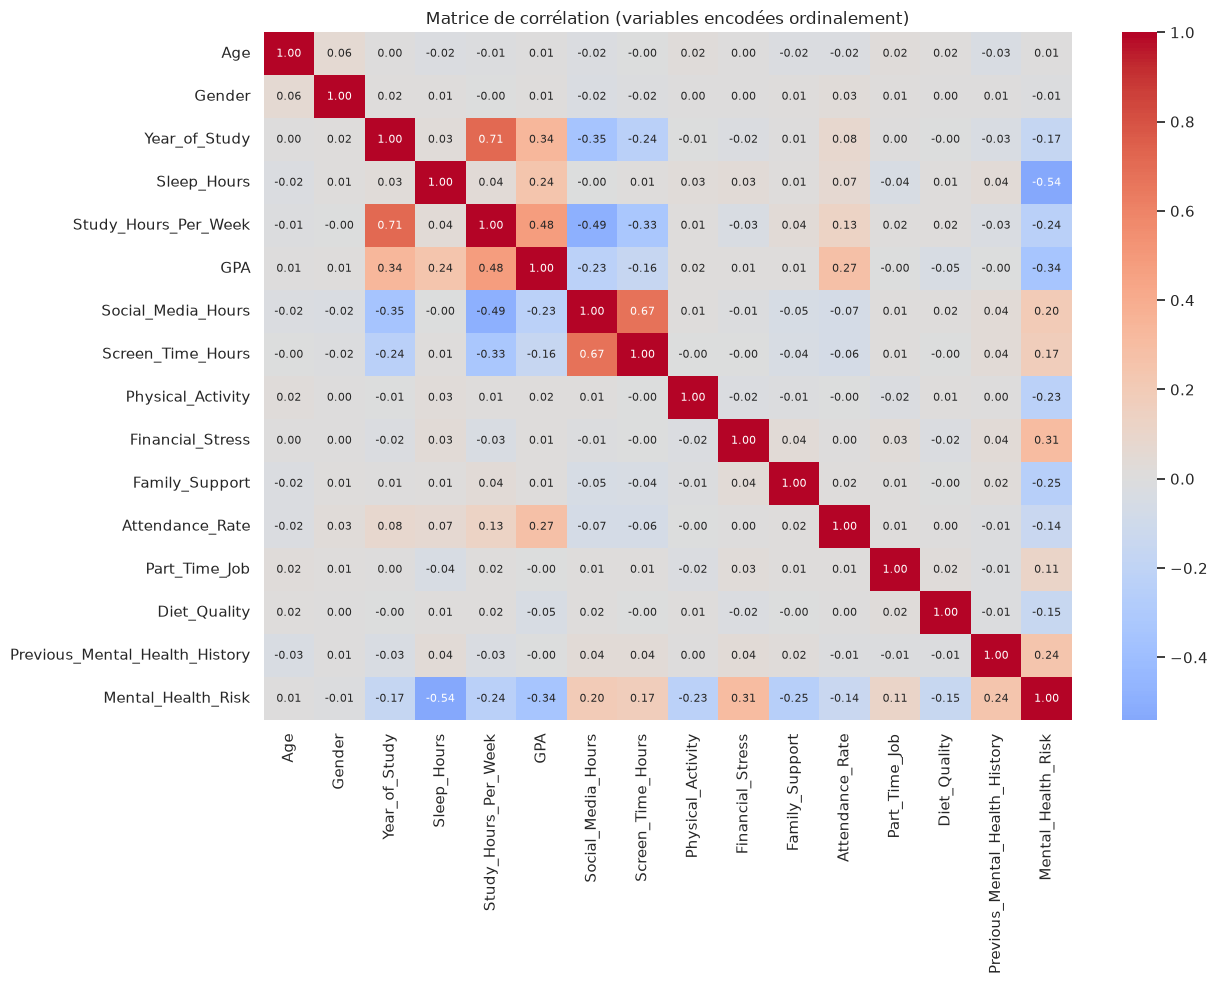

In [19]:

df_enc = df.copy()
df_enc["Gender"] = df_enc["Gender"].map({"Male": 0, "Female": 1, "Non-binary": 2})
df_enc["Physical_Activity"] = df_enc["Physical_Activity"].map({"Low": 0, "Moderate": 1, "High": 2})
df_enc["Diet_Quality"] = df_enc["Diet_Quality"].map({"Poor": 0, "Average": 1, "Good": 2})
df_enc["Part_Time_Job"] = df_enc["Part_Time_Job"].map({"No": 0, "Yes": 1})
df_enc["Previous_Mental_Health_History"] = df_enc["Previous_Mental_Health_History"].map({"No": 0, "Yes": 1})
df_enc["Mental_Health_Risk"] = df_enc["Mental_Health_Risk"].map({"Low": 0, "Medium": 1, "High": 2})
df_enc = df_enc.drop(columns=["Student_ID"])

corr_matrix = df_enc.corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Matrice de corrélation (variables encodées ordinalement)")
plt.tight_layout()
plt.show()